# Exploratory Data Analysis (EDA)

## Objective

This notebook explores the processed collision-level dataset before model training.

The EDA focuses on:

- the distribution of the binary target;
- class imbalance;
- relationships between collision characteristics and injury severity;
- categorical comparisons;
- trends over time;
- numeric and binary feature relationships.

Each visualization includes a title, labeled axes, and a short interpretation.

### Load the Processed Collision Dataset

This step imports the required libraries, locates the project root, and loads the cleaned collision-level dataset from the `data/processed/` folder. Using the processed dataset ensures that the exploratory analysis is performed on the same cleaned data that will later be used for modelling and the dashboard.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Locate project root
project_root = Path.cwd()

if project_root.name == "notebooks":
    project_root = project_root.parent

# Load processed collision-level dataset
data_path = (
    project_root
    / "data"
    / "processed"
    / "processed_collisions.csv"
)

df = pd.read_csv(data_path)

print("Dataset shape:", df.shape)
df.head()

Dataset shape: (7610, 30)


,collision_id,accdate,stname1,stname2,per_inv,acclass,accloc,traffictl,impactype,visible,...,distracted,cyclist,motorcyclist,other_micromobility,older_adult,pedestrian,red_light,school_child,heavy_truck,target
0,2006:893184,2006-01-01T02:36:00,WOODBINE AVE,O CONNOR DR,8,Non-Fatal Injury,Intersection-Related,No Control,Approaching Head On,Clear,...,False,False,False,False,False,False,False,True,False,0
1,2006:909646,2006-01-01T03:15:00,DANFORTH AVE,WEST LYNN AVE,5,Non-Fatal Injury,Intersection-Related,No Control,SMV Other,Snow,...,True,False,False,False,False,False,False,True,False,0
2,2026:6000734335,2026-04-10T06:10:00,ALBION RD,FINCH AV W,3,Non-Fatal Injury,Intersection-Related,Traffic Signal,SMV Other,Rain,...,False,False,False,False,False,True,False,False,False,0
3,2026:6001470477,2026-07-15T18:33:00,28 CARNFORTH RD,LAWRENCE AV E,2,Non-Fatal Injury,Non-Intersection,Unknown,Approaching Head On,Clear,...,False,False,True,False,False,False,False,True,False,0
4,2026:6001482161,2026-07-17T09:39:00,HIGHWAY 2A E,MEADOWVALE RD,5,Non-Fatal Injury,Non-Intersection,No Control,Rear End,Clear,...,False,False,False,False,False,False,False,True,False,0


### Examine the Target Class Distribution

This step counts the number of Fatal Injury and Non-Fatal Injury collisions and visualizes the class distribution with a bar chart. Reviewing the target balance is important because a strong class imbalance can affect model training and make accuracy alone a misleading evaluation metric.

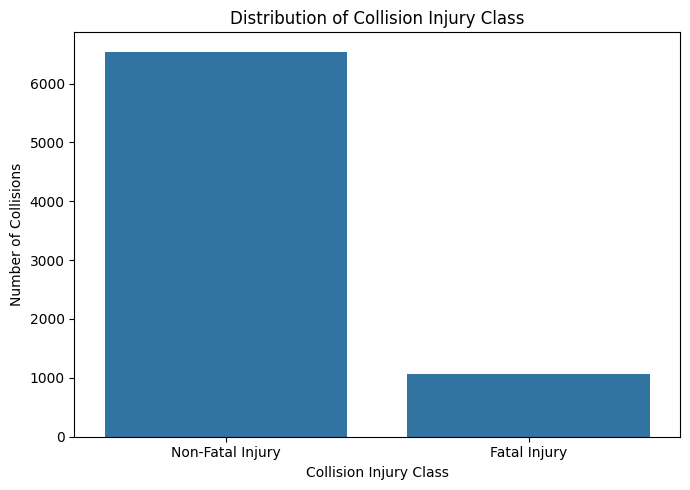

In [2]:
# Count target classes
target_counts = df["acclass"].value_counts()

# Plot target distribution
plt.figure(figsize=(7, 5))

sns.barplot(
    x=target_counts.index,
    y=target_counts.values
)

plt.title("Distribution of Collision Injury Class")
plt.xlabel("Collision Injury Class")
plt.ylabel("Number of Collisions")

plt.tight_layout()
plt.show()

**Interpretation:** Non-Fatal Injury collisions are much more common than Fatal Injury collisions, showing that the target variable is imbalanced and this imbalance will need to be considered during model training and evaluation.

### Compare Fatal Injury Rates by Impact Type

This step calculates the percentage of Fatal Injury collisions for each collision impact type and visualizes the results with a horizontal bar chart. Comparing fatality rates across impact categories helps identify which types of collisions are associated with more severe outcomes.

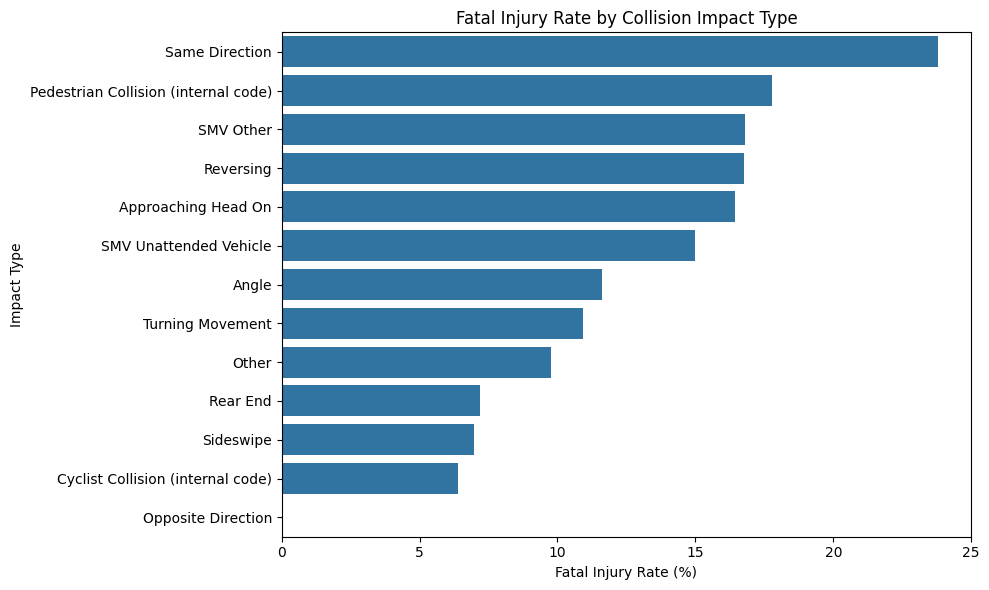

In [3]:
# Calculate fatality rate by impact type
impact_fatality_rate = (
    df.groupby("impactype")["target"]
    .mean()
    .sort_values(ascending=False)
    .reset_index()
)

# Convert proportion to percentage
impact_fatality_rate["fatality_rate"] = (
    impact_fatality_rate["target"] * 100
)

# Plot
plt.figure(figsize=(10, 6))

sns.barplot(
    data=impact_fatality_rate,
    x="fatality_rate",
    y="impactype"
)

plt.title("Fatal Injury Rate by Collision Impact Type")
plt.xlabel("Fatal Injury Rate (%)")
plt.ylabel("Impact Type")

plt.tight_layout()
plt.show()

**Interpretation:** Fatal injury rates vary by collision impact type. Although Same Direction collisions have the highest observed fatality rate, this category contains only 21 collisions, while Pedestrian Collisions show a high fatality rate across a much larger number of observations.

### Summarize Impact Type Counts and Fatality Rates

This step creates a detailed summary for each collision impact type, including the total number of collisions, the number of fatal collisions, and the fatality rate. Including the collision counts helps interpret the fatality percentages more carefully, especially for categories with only a small number of observations.

In [4]:
impact_summary = (
    df.groupby("impactype")
    .agg(
        collision_count=("target", "size"),
        fatal_collisions=("target", "sum"),
        fatality_rate=("target", "mean")
    )
    .sort_values("fatality_rate", ascending=False)
)

impact_summary["fatality_rate"] = (
    impact_summary["fatality_rate"] * 100
).round(2)

impact_summary

,collision_count,fatal_collisions,fatality_rate
impactype,,,
Same Direction,21,5,23.81
Pedestrian Collision (internal code),2926,520,17.77
SMV Other,1071,180,16.81
Reversing,203,34,16.75
Approaching Head On,286,47,16.43
SMV Unattended Vehicle,80,12,15.00
Angle,387,45,11.63
Turning Movement,1051,115,10.94
Other,82,8,9.76


### Compare People Involved by Injury Class

This step uses a boxplot to compare the distribution of `per_inv`, the number of people involved in a collision, between Fatal Injury and Non-Fatal Injury outcomes. The comparison helps determine whether collision severity appears to differ based on how many people were involved.

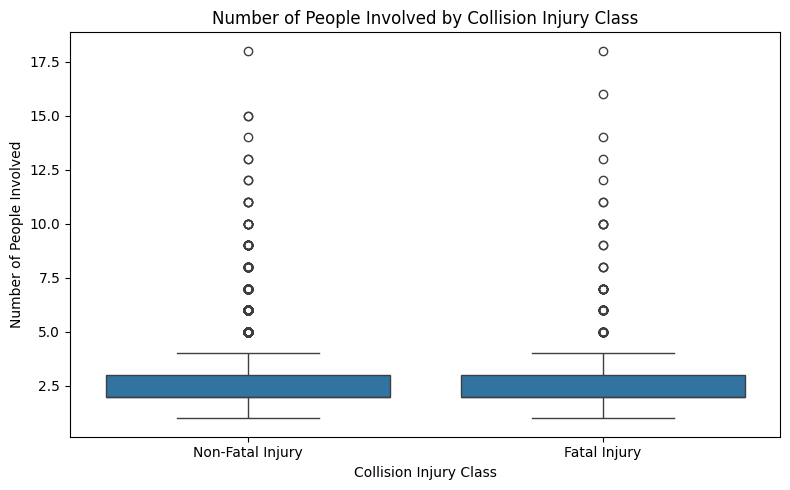

In [5]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="acclass",
    y="per_inv"
)

plt.title("Number of People Involved by Collision Injury Class")
plt.xlabel("Collision Injury Class")
plt.ylabel("Number of People Involved")

plt.tight_layout()
plt.show()

**Interpretation:** The number of people involved is distributed similarly for Fatal and Non-Fatal collisions, suggesting that `per_inv` alone may not strongly distinguish collision severity.

### Examine Fatal Injury Rate Over Time

This step converts the collision date to a datetime format, extracts the collision year, and calculates the annual Fatal Injury rate. Plotting the yearly trend helps identify whether collision severity has changed over time and whether later years show different patterns from earlier years.

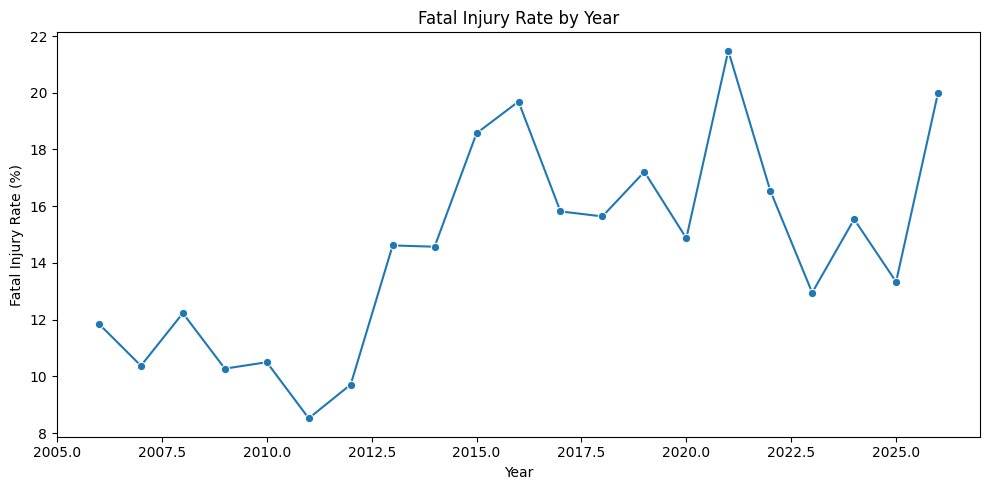

In [6]:
# Convert collision date to datetime
df["accdate"] = pd.to_datetime(df["accdate"])

# Extract year
df["year"] = df["accdate"].dt.year

# Calculate fatal injury rate by year
yearly_fatality_rate = (
    df.groupby("year")["target"]
    .mean()
    .mul(100)
    .reset_index(name="fatality_rate")
)

plt.figure(figsize=(10, 5))

sns.lineplot(
    data=yearly_fatality_rate,
    x="year",
    y="fatality_rate",
    marker="o"
)

plt.title("Fatal Injury Rate by Year")
plt.xlabel("Year")
plt.ylabel("Fatal Injury Rate (%)")

plt.tight_layout()
plt.show()

**Interpretation:** The fatal injury rate generally increased from the earlier years of the dataset and remained more variable at higher levels in later years, indicating that collision severity patterns changed over time.

### Compare Fatal Injury Rates by Lighting Condition

This step calculates the Fatal Injury rate for each lighting condition and visualizes the results with a bar chart. Comparing collision severity across lighting conditions helps determine whether reduced visibility or nighttime conditions are associated with higher fatality rates.

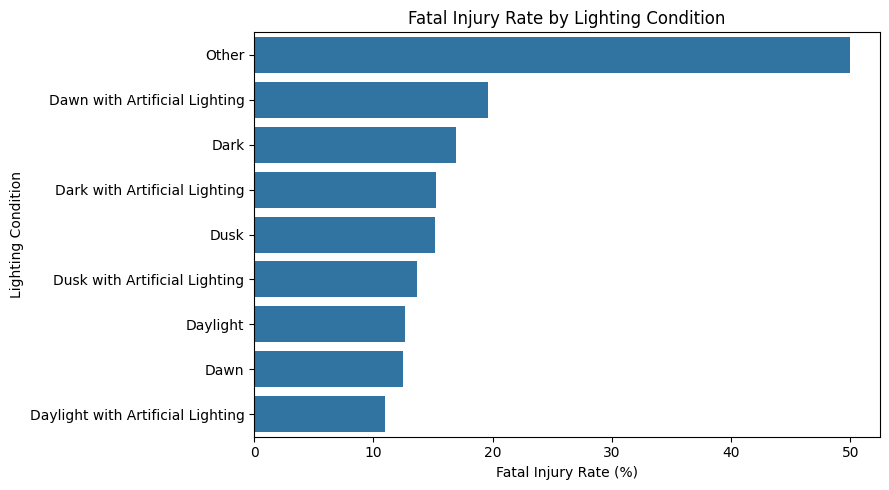

In [7]:
light_fatality_rate = (
    df.groupby("light")["target"]
    .mean()
    .mul(100)
    .sort_values(ascending=False)
    .reset_index(name="fatality_rate")
)

plt.figure(figsize=(9, 5))

sns.barplot(
    data=light_fatality_rate,
    x="fatality_rate",
    y="light"
)

plt.title("Fatal Injury Rate by Lighting Condition")
plt.xlabel("Fatal Injury Rate (%)")
plt.ylabel("Lighting Condition")

plt.tight_layout()
plt.show()

**Interpretation:** Dark and Dark with Artificial Lighting conditions have higher fatal injury rates than Daylight conditions, while the very high rate for the Other category is based on only two collisions and should be interpreted cautiously.

### Summarize Lighting Condition Counts and Fatality Rates

This step creates a detailed summary for each lighting condition, including the total number of collisions, the number of fatal collisions, and the fatality rate. Including the collision counts makes it easier to interpret the percentages carefully, especially for lighting categories with only a small number of observations.

In [8]:
light_summary = (
    df.groupby("light")
    .agg(
        collision_count=("target", "size"),
        fatal_collisions=("target", "sum"),
        fatality_rate=("target", "mean")
    )
    .sort_values("fatality_rate", ascending=False)
)

light_summary["fatality_rate"] = (
    light_summary["fatality_rate"] * 100
).round(2)

light_summary

,collision_count,fatal_collisions,fatality_rate
light,,,
Other,2,1,50.00
Dawn with Artificial Lighting,51,10,19.61
Dark,1314,222,16.89
Dark with Artificial Lighting,1577,241,15.28
Dusk,99,15,15.15
Dusk with Artificial Lighting,117,16,13.68
Daylight,4320,547,12.66
Dawn,48,6,12.50
Daylight with Artificial Lighting,82,9,10.98


### Compare Fatal Injury Rates by Road Surface Condition

This step calculates the Fatal Injury rate for each road surface condition and visualizes the differences across categories. The comparison helps identify whether certain surface conditions, such as wet or snow-covered roads, are associated with more severe collision outcomes.

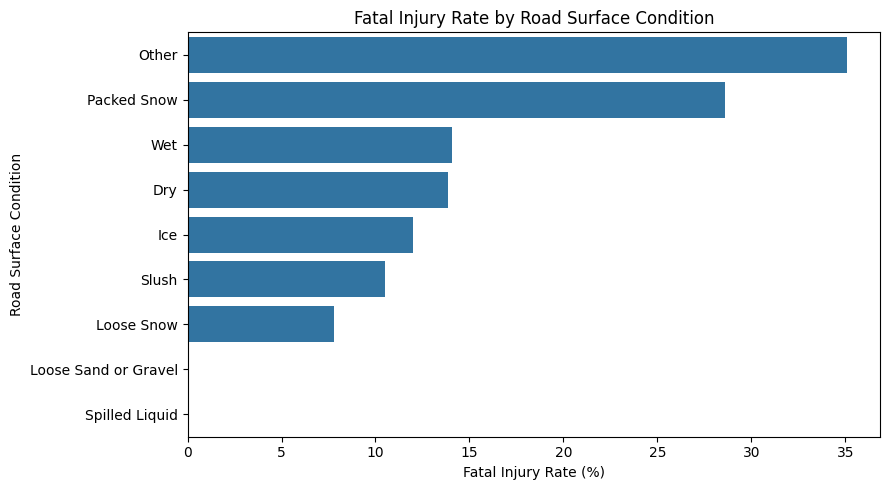

In [9]:
road_surface_fatality_rate = (
    df.groupby("rdsfcond")["target"]
    .mean()
    .mul(100)
    .sort_values(ascending=False)
    .reset_index(name="fatality_rate")
)

plt.figure(figsize=(9, 5))

sns.barplot(
    data=road_surface_fatality_rate,
    x="fatality_rate",
    y="rdsfcond"
)

plt.title("Fatal Injury Rate by Road Surface Condition")
plt.xlabel("Fatal Injury Rate (%)")
plt.ylabel("Road Surface Condition")

plt.tight_layout()
plt.show()

**Interpretation:** Dry and Wet road surfaces have very similar fatal injury rates despite representing most collisions, while the higher rates observed for Other and Packed Snow conditions are based on much smaller numbers of collisions and should be interpreted cautiously.

### Summarize Road Surface Counts and Fatality Rates

This step creates a detailed summary for each road surface condition, including the total number of collisions, the number of fatal collisions, and the fatality rate. Including the collision counts helps distinguish meaningful patterns from percentages based on only a small number of observations.

In [10]:
road_surface_summary = (
    df.groupby("rdsfcond")
    .agg(
        collision_count=("target", "size"),
        fatal_collisions=("target", "sum"),
        fatality_rate=("target", "mean")
    )
    .sort_values("fatality_rate", ascending=False)
)

road_surface_summary["fatality_rate"] = (
    road_surface_summary["fatality_rate"] * 100
).round(2)

road_surface_summary

,collision_count,fatal_collisions,fatality_rate
rdsfcond,,,
Other,57,20,35.09
Packed Snow,21,6,28.57
Wet,1272,179,14.07
Dry,6126,850,13.88
Ice,25,3,12.00
Slush,38,4,10.53
Loose Snow,64,5,7.81
Loose Sand or Gravel,6,0,0.00
Spilled Liquid,1,0,0.00


### Examine Correlations Between Selected Features and Collision Severity

This step calculates a correlation matrix for the target variable and selected numeric and binary collision features. Boolean indicators are converted to integers so they can be included in the calculation. The heatmap helps identify whether any individual feature has a strong linear relationship with Fatal Injury outcomes.

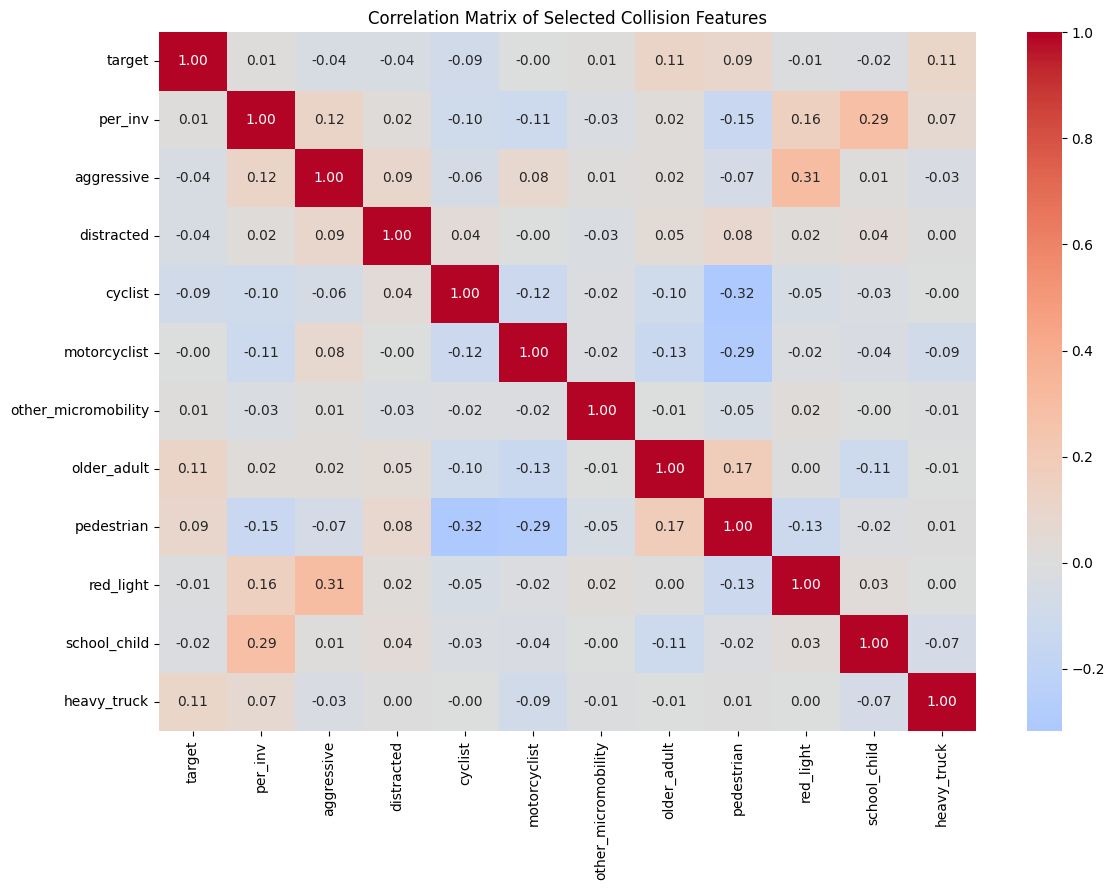

In [11]:
# Select numeric and binary features for correlation analysis
correlation_columns = [
    "target",
    "per_inv",
    "aggressive",
    "distracted",
    "cyclist",
    "motorcyclist",
    "other_micromobility",
    "older_adult",
    "pedestrian",
    "red_light",
    "school_child",
    "heavy_truck"
]

correlation_df = df[correlation_columns].copy()

# Convert Boolean columns to integers
boolean_columns = correlation_df.select_dtypes(include="bool").columns
correlation_df[boolean_columns] = correlation_df[boolean_columns].astype(int)

# Calculate correlation matrix
correlation_matrix = correlation_df.corr()

plt.figure(figsize=(12, 9))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Matrix of Selected Collision Features")

plt.tight_layout()
plt.show()

**Interpretation:** The selected numeric and binary features show only weak linear correlations with the target, suggesting that collision severity is likely influenced by combinations of factors rather than any single strongly correlated feature.

## EDA Summary

The exploratory data analysis identified several important patterns in the processed collision dataset:

- The target variable is imbalanced, with Non-Fatal Injury collisions occurring much more frequently than Fatal Injury collisions.
- Fatal injury rates differ across collision impact types, although some of the highest rates are based on small sample sizes and should be interpreted cautiously.
- The number of people involved in a collision (`per_inv`) is distributed similarly between Fatal and Non-Fatal collisions, suggesting limited predictive value when considered alone.
- Fatal injury rates generally increased from the earlier years of the dataset and became more variable in later years.
- Dark lighting conditions show higher fatal injury rates than daylight conditions, while categories with very few observations should not be over-interpreted.
- Dry and Wet road surface conditions have similar fatal injury rates despite representing most of the collisions.
- The selected numeric and binary features show only weak linear correlations with the target, suggesting that collision severity is likely influenced by multiple interacting factors rather than one dominant feature.

Overall, the EDA suggests that the prediction task will likely benefit from models that can capture nonlinear relationships and interactions between features. The observed class imbalance will also need to be considered during model training and evaluation.